 # 导入所需库与数据

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import pure_eval
import seaborn as sns
import sklearn
import xgboost as xgb
import optuna
import lightgbm as lgb
from IPython.core.pylabtools import figsize
from optuna.study import study
from scipy.stats import alpha


##导入数据
train=pd.read_csv("train.csv")
test=pd.read_csv("test.csv")
data=pd.concat([train,test],axis=0)
data=data.drop("Id",axis=1).reset_index(drop=True)##id列对于数据的预测没有影响，故删除
pure_features=data.drop("SalePrice",axis=1).reset_index(drop=True)
print(data.head())

D:\桌面\pycharm\kaggle房价预测\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


   MSSubClass MSZoning  LotFrontage  LotArea Street Alley LotShape  \
0          60       RL         65.0     8450   Pave   NaN      Reg   
1          20       RL         80.0     9600   Pave   NaN      Reg   
2          60       RL         68.0    11250   Pave   NaN      IR1   
3          70       RL         60.0     9550   Pave   NaN      IR1   
4          60       RL         84.0    14260   Pave   NaN      IR1   

  LandContour Utilities LotConfig  ... PoolArea PoolQC Fence MiscFeature  \
0         Lvl    AllPub    Inside  ...        0    NaN   NaN         NaN   
1         Lvl    AllPub       FR2  ...        0    NaN   NaN         NaN   
2         Lvl    AllPub    Inside  ...        0    NaN   NaN         NaN   
3         Lvl    AllPub    Corner  ...        0    NaN   NaN         NaN   
4         Lvl    AllPub       FR2  ...        0    NaN   NaN         NaN   

  MiscVal MoSold  YrSold  SaleType  SaleCondition  SalePrice  
0       0      2    2008        WD         Normal   208500.

# 探索性数据分析

In [2]:
# 先对特征进行分类

numerical_features=[col for col in data.select_dtypes(include=['int64','float64']).columns]
categorical_features=[col for col in data.select_dtypes(include=['object']).columns]
continupous_features=[col for col in numerical_features if len(data[col].unique())>=20]
discrete_features=[col for col in numerical_features if len(data[col].unique())<20]

print(numerical_features)
print(categorical_features)
print(continupous_features)
print(discrete_features)
print(f"数值型与类别型的总和为{len(numerical_features+categorical_features)}")

['MSSubClass', 'LotFrontage', 'LotArea', 'OverallQual', 'OverallCond', 'YearBuilt', 'YearRemodAdd', 'MasVnrArea', 'BsmtFinSF1', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', '1stFlrSF', '2ndFlrSF', 'LowQualFinSF', 'GrLivArea', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath', 'HalfBath', 'BedroomAbvGr', 'KitchenAbvGr', 'TotRmsAbvGrd', 'Fireplaces', 'GarageYrBlt', 'GarageCars', 'GarageArea', 'WoodDeckSF', 'OpenPorchSF', 'EnclosedPorch', '3SsnPorch', 'ScreenPorch', 'PoolArea', 'MiscVal', 'MoSold', 'YrSold', 'SalePrice']
['MSZoning', 'Street', 'Alley', 'LotShape', 'LandContour', 'Utilities', 'LotConfig', 'LandSlope', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType', 'HouseStyle', 'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType', 'ExterQual', 'ExterCond', 'Foundation', 'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2', 'Heating', 'HeatingQC', 'CentralAir', 'Electrical', 'KitchenQual', 'Functional', 'FireplaceQu', 'GarageType', 'GarageFinish', 'GarageQual

C:\Users\zyb\AppData\Local\Temp\ipykernel_13960\561643638.py:4: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features=[col for col in data.select_dtypes(include=['object']).columns]


In [3]:
# 缺失情况查看
train_lost_imformation=train.isna().mean().sort_values(ascending=False).head(20)
test_lost_imformation=test.isna().mean().sort_values(ascending=False).head(20)
lost_imformation_combat=pd.concat([train_lost_imformation,test_lost_imformation],axis=1)
print(lost_imformation_combat)


                     0         1
PoolQC        0.995205  0.997944
MiscFeature   0.963014  0.965045
Alley         0.937671  0.926662
Fence         0.807534  0.801234
MasVnrType    0.597260  0.612748
FireplaceQu   0.472603  0.500343
LotFrontage   0.177397  0.155586
GarageQual    0.055479  0.053461
GarageFinish  0.055479  0.053461
GarageType    0.055479  0.052090
GarageYrBlt   0.055479  0.053461
GarageCond    0.055479  0.053461
BsmtFinType2  0.026027  0.028787
BsmtExposure  0.026027  0.030158
BsmtCond      0.025342  0.030843
BsmtQual      0.025342  0.030158
BsmtFinType1  0.025342  0.028787
MasVnrArea    0.005479  0.010281
Electrical    0.000685       NaN
Condition2    0.000000       NaN
MSZoning           NaN  0.002742
BsmtHalfBath       NaN  0.001371


In [4]:
##对于不同类特征缺失值统计
categorical_features_lost=pure_features[categorical_features].isna().mean().sort_values(ascending=False).head(20)
numerical_features.remove("SalePrice")
numerical_features_lost=pure_features[numerical_features].isna().mean().sort_values(ascending=False)
print(categorical_features_lost)
print(numerical_features_lost)

PoolQC          0.996574
MiscFeature     0.964029
Alley           0.932169
Fence           0.804385
MasVnrType      0.605002
FireplaceQu     0.486468
GarageCond      0.054471
GarageQual      0.054471
GarageFinish    0.054471
GarageType      0.053786
BsmtCond        0.028092
BsmtExposure    0.028092
BsmtQual        0.027749
BsmtFinType2    0.027407
BsmtFinType1    0.027064
MSZoning        0.001370
Utilities       0.000685
Functional      0.000685
Exterior2nd     0.000343
Exterior1st     0.000343
dtype: float64
LotFrontage      0.166495
GarageYrBlt      0.054471
MasVnrArea       0.007879
BsmtFullBath     0.000685
BsmtHalfBath     0.000685
GarageCars       0.000343
BsmtFinSF2       0.000343
GarageArea       0.000343
TotalBsmtSF      0.000343
BsmtFinSF1       0.000343
BsmtUnfSF        0.000343
MSSubClass       0.000000
OverallQual      0.000000
LotArea          0.000000
YearBuilt        0.000000
2ndFlrSF         0.000000
GrLivArea        0.000000
OverallCond      0.000000
1stFlrSF         

类型类特征缺失值较多（如PoolQC等），通过查阅data_discription可知，类型类缺失值一般意味着不存在该设施（如没有泳池），考虑用字符串"None"填充。
数值型特征除LotFrontage,GarageYrBlt外缺失值很少，可知GarageYrBlt缺失原因是因为没有车库，属于结构性缺失，采用指示列+众数填充（为了树模型与线性回归模型均可使用做考虑，若打定主意使用树模型可以直接负数填充），LotFrontage用强相关特征回归填充，其余数值型特征离散型用众数填充，连续型用均值填充。


SalePrice的偏度为1.8828757597682129


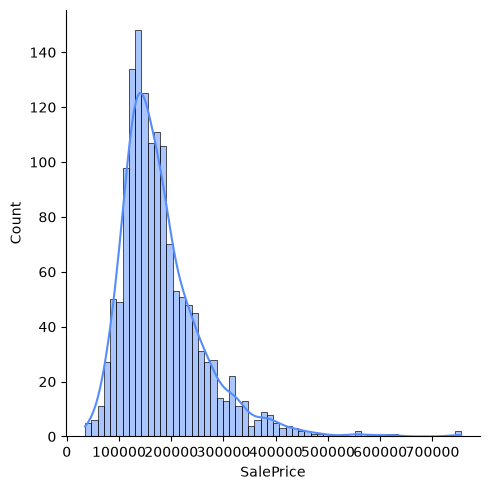

In [5]:
##房价分布情况查看与偏度计算
sns.displot(train["SalePrice"],bins=60,kde=True)
print(f"SalePrice的偏度为{train["SalePrice"].skew()}")

房价偏度过高，考虑线性回归模型的使用可能，后续应进行正态化处理

MiscVal          21.958480
LotArea          12.829025
LowQualFinSF     12.094977
3SsnPorch        11.381914
BsmtFinSF2        4.147456
EnclosedPorch     4.005950
ScreenPorch       3.948723
MasVnrArea        2.602589
OpenPorchSF       2.536417
WoodDeckSF        1.843380
LotFrontage       1.503278
1stFlrSF          1.470360
BsmtFinSF1        1.425722
GrLivArea         1.270010
TotalBsmtSF       1.162882
BsmtUnfSF         0.919824
2ndFlrSF          0.862118
GarageArea        0.241301
GarageYrBlt      -0.382150
YearRemodAdd     -0.451252
YearBuilt        -0.600114
dtype: float64


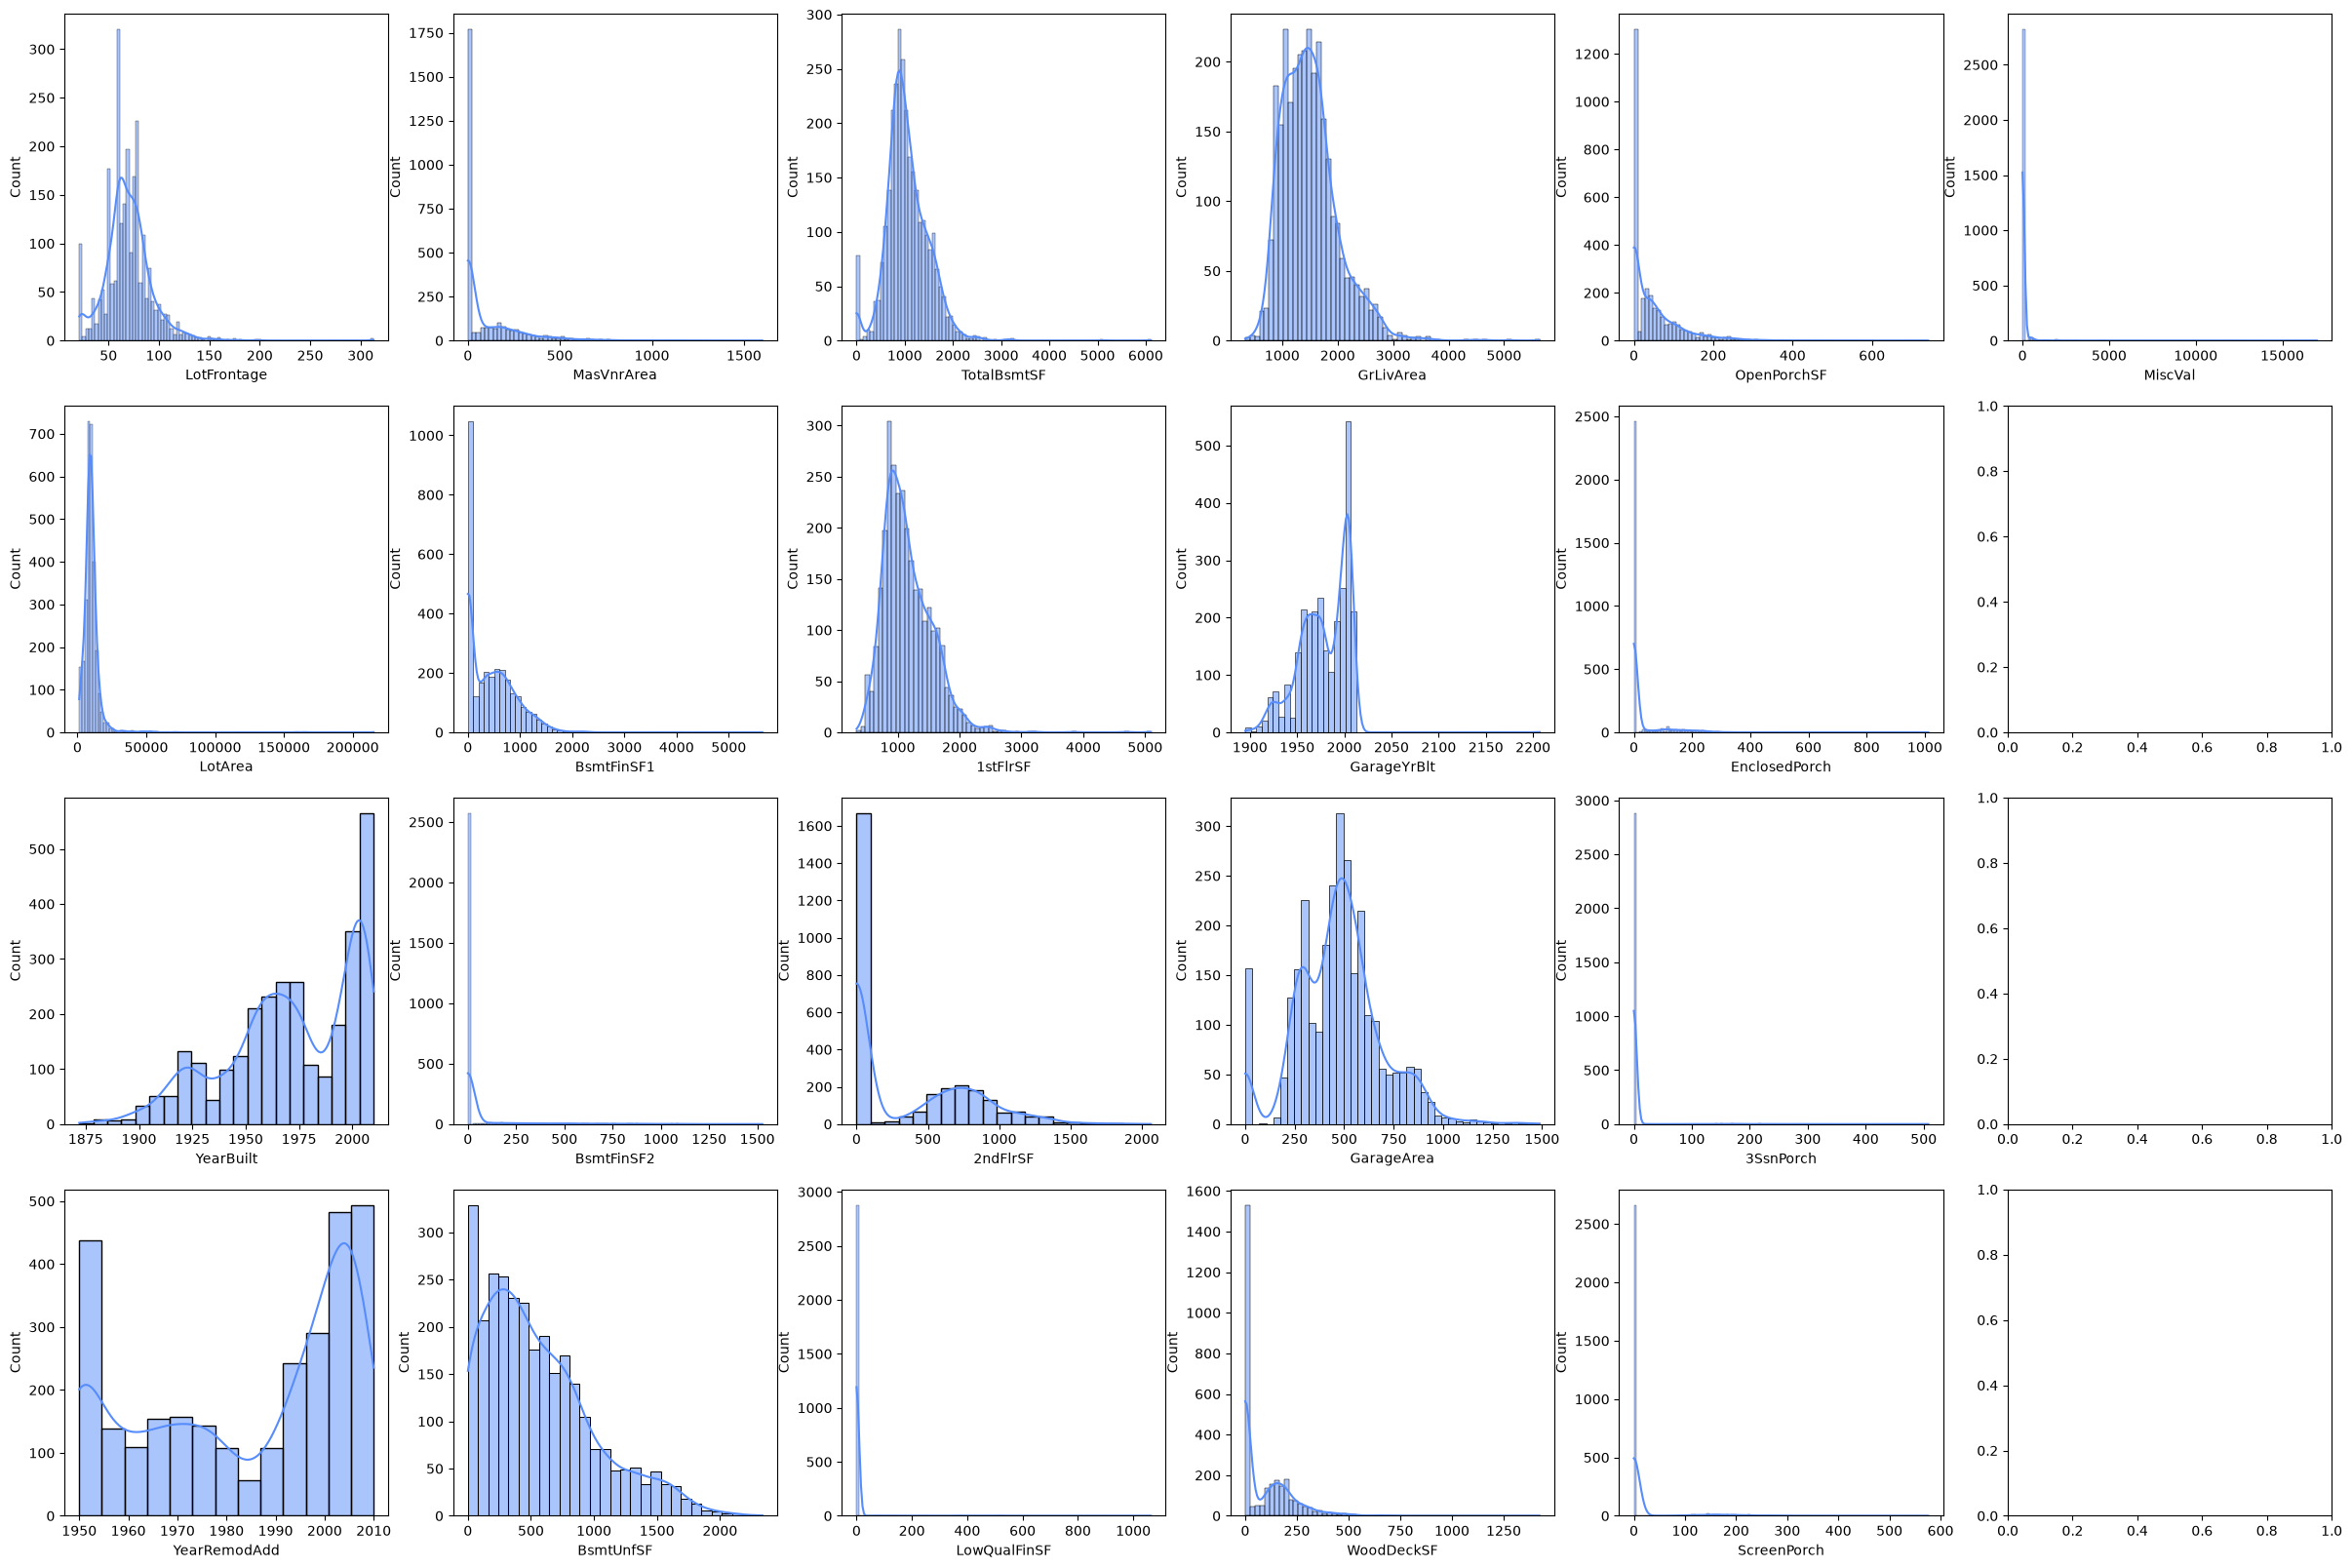

In [6]:
## 连续型特征分布情况与偏度计算
continupous_features.remove("SalePrice")
f,axes=plt.subplots(4,6,figsize=(30,20),sharex=False)
for i,features in enumerate(continupous_features):
    sns.histplot(data=pure_features,x=features,ax=axes[i%4,i//4],kde=True)

skewed_features=data[continupous_features].apply(lambda x:x.skew()).sort_values(ascending=False)
print(skewed_features)

可知存在许多连续型数值特征偏度过大，计划将对偏度大于1的特征进行取对正态化处理

<Axes: >

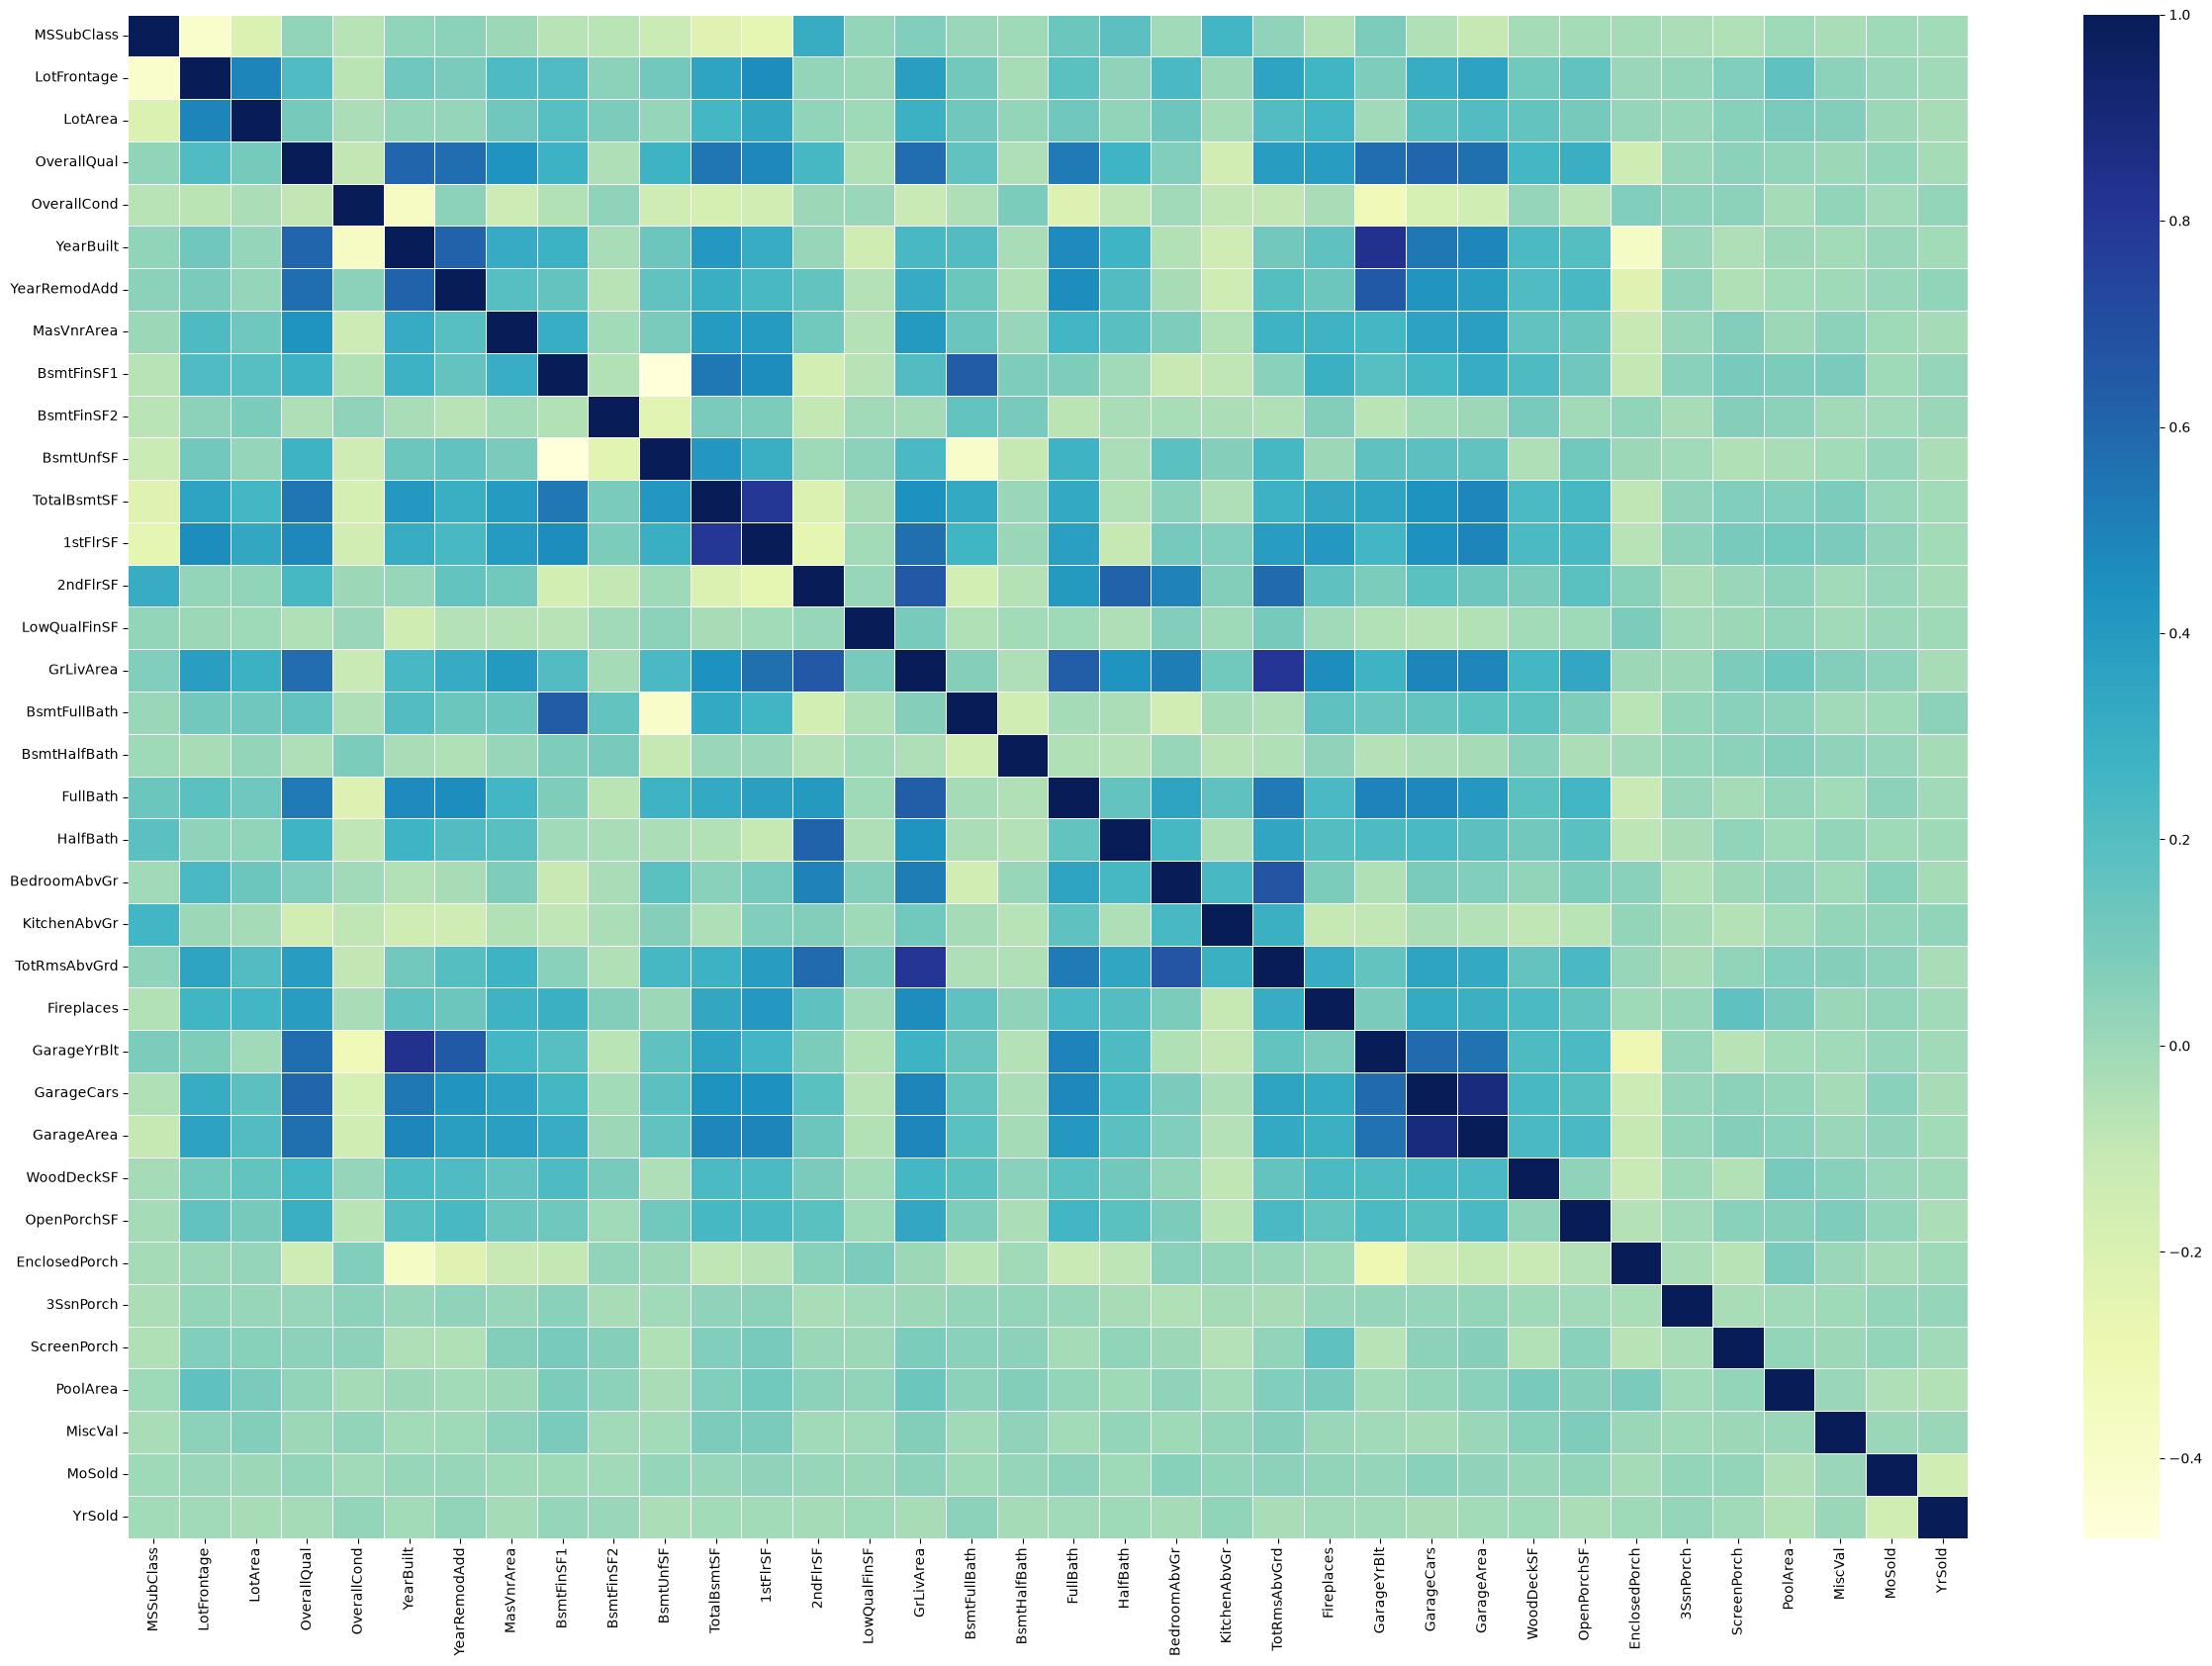

In [7]:
## 用热图分析数值型特征之间相关性
plt.figure(figsize=(30,20))
sns.heatmap(data[numerical_features].corr(),cmap="YlGnBu",linewidths=.5)

# 数据预处理

In [8]:
## 缺失值填充

##类型类特征缺失值填充方案：缺失数量高的采用字符串“None”填充，代表结构性缺失；缺失数量低的用众数填充。
high_lose_cate=[col for col in categorical_features if data[col].isna().sum()>=80]
low_lose_cate=[col for col in categorical_features if data[col].isna().sum()<80]
for col in high_lose_cate:
    data[col]=data[col].fillna("None")
for col in low_lose_cate:
    data[col]=data[col].fillna(data[col].mode()[0])

##数值型类型缺失值填充方案：GarageYrBlt列指示列+众数填充；LotFrontage用强相关特征回归填充；其余数值型特征离散型用众数填充；连续型用均值填充
data["HasGarage"] = data["GarageYrBlt"].notna().astype(int)
data["GarageYrBlt"] = data["GarageYrBlt"].fillna(data["GarageYrBlt"].mode()[0])

from sklearn.ensemble import RandomForestRegressor
predictors = ["LotArea", "1stFlrSF"]
X_full = data[predictors + ["LotFrontage"]]
known = X_full[X_full["LotFrontage"].notna()]     # 有值的（用于训练）
unknown = X_full[X_full["LotFrontage"].isna()]    # 缺失的（用于预测）
X_train = known[predictors]
y_train = known["LotFrontage"]
model = RandomForestRegressor(n_estimators=100, random_state=42)
model.fit(X_train, y_train)
data.loc[data["LotFrontage"].isna(), "LotFrontage"] =model.predict(unknown[predictors])

for col in discrete_features:
    data[col]=data[col].fillna(data[col].mode()[0])
for col in continupous_features:
    data[col]=data[col].fillna(data[col].mean())

##查看缺失值填充情况
data.isnull().sum().sort_values(ascending=False).head

<bound method NDFrame.head of SalePrice        1459
MSZoning            0
LotFrontage         0
LotArea             0
Street              0
                 ... 
MiscVal             0
YrSold              0
SaleType            0
SaleCondition       0
HasGarage           0
Length: 81, dtype: int64>

In [9]:
## 房价及高偏度连续型数值型特征正态化
data["SalePrice"]=np.log1p(data["SalePrice"])
print(f"正态化后SalePrice的偏度为{data["SalePrice"].skew()}")

high_skew_feateres=[]
for feature,skew_value in skewed_features.items():
    if skew_value>1:
        high_skew_feateres.append(feature)
for i in high_skew_feateres:
    data[i]=np.log1p(data[i])
skewed_features=data[continupous_features].apply(lambda x:x.skew()).sort_values(ascending=False)
print(skewed_features)

正态化后SalePrice的偏度为0.12134661989685333
3SsnPorch        8.829794
LowQualFinSF     8.562091
MiscVal          5.216665
ScreenPorch      2.947420
BsmtFinSF2       2.459779
EnclosedPorch    1.962089
BsmtUnfSF        0.919981
2ndFlrSF         0.862118
MasVnrArea       0.504832
GarageArea       0.241342
WoodDeckSF       0.158114
1stFlrSF         0.064861
GrLivArea        0.013194
OpenPorchSF     -0.041819
YearRemodAdd    -0.451252
GarageYrBlt     -0.468752
LotArea         -0.505010
YearBuilt       -0.600114
BsmtFinSF1      -0.618503
LotFrontage     -0.932853
TotalBsmtSF     -4.984298
dtype: float64


# 编码数据集后切分数据集

In [10]:
data=pd.get_dummies(data,dtype=int)
new_train=data.iloc[:len(train),:]
new_test=data.iloc[len(train):,:]
x_train=new_train.drop("SalePrice",axis=1)
y_train=new_train["SalePrice"]
x_test=new_test.drop("SalePrice",axis=1)


# 建立模型

In [11]:
from sklearn.linear_model import LinearRegression
from sklearn.linear_model import Ridge
from sklearn.ensemble import GradientBoostingRegressor
import lightgbm
from xgboost import XGBRegressor
from sklearn.model_selection import cross_val_score


def tune(objective):
    study = optuna.create_study(direction="maximize")
    study.optimize(objective, n_trials=100)
    params = study.best_params
    best_score=study.best_value
    print(f"best_score:{best_score}")
    return params

def ridge(trial):
    alpha=trial.suggest_float("alpha",0.1,30)
    ridge=Ridge(alpha=alpha)
    score=cross_val_score(ridge,x_train,y_train,cv=10,scoring="neg_mean_squared_error").mean()
    return score

def gbr(trial):
    n_estimators=trial.suggest_int("n_estimators",50,2000)
    learning_rate=trial.suggest_float("learning_rate",0.01,0.3)
    max_depth=trial.suggest_int("max_depth",1,30)
    gbr=GradientBoostingRegressor(
        n_estimators=n_estimators,
        learning_rate=learning_rate,
        max_depth=max_depth,
        random_state=1,
    )
    score=cross_val_score(gbr,x_train,y_train,cv=10,scoring="neg_mean_squared_error").mean()
    return score

def xgb(trial):
    n_estimators=trial.suggest_int("n_estimators",500,2000)
    learning_rate=trial.suggest_float("learning_rate",0.01,0.3)
    max_depth=trial.suggest_int("max_depth",1,30)
    xgb=XGBRegressor(
        n_estimators=n_estimators,
        learning_rate=learning_rate,
        max_depth=max_depth,
    )
    score=cross_val_score(xgb,x_train,y_train,cv=10,scoring="neg_mean_squared_error").mean()
    return score

def lgb(trial):
    num_leaves=trial.suggest_int("num_leaves", 10, 100)
    max_depth=trial.suggest_int("max_depth", 3, 30)
    learning_rate= trial.suggest_float("learning_rate", 0.01, 0.3, log=True)
    n_estimators=trial.suggest_int("n_estimators", 100, 1500)
    lgb=lightgbm.LGBMRegressor(
        num_leaves=num_leaves,
        max_depth=max_depth,
        learning_rate=learning_rate,
        n_estimators=n_estimators,
        verbosity=-1,
    )
    score=cross_val_score(lgb,x_train,y_train,cv=10,scoring="neg_mean_squared_error").mean()
    return score

In [ ]:
ridge_params=tune(ridge)
gbr_params=tune(gbr)
xgb_params=tune(xgb)
lgb_params=tune(lgb)
##得到gbr的模型分数最好，选用gbr模型进行预测


In [ ]:
gbr=GradientBoostingRegressor(**gbr_params)

gbr.fit(x_train,y_train)
predictions=np.expm1(gbr.predict(x_test))
Id=test["Id"]
submission=pd.DataFrame({"Id":Id,"SalePrice":predictions})
submission.to_csv("submission_gbr.csv",index=False)